# Problema 3 — Classificação de vinhos com k-NN

## Tarefa 1 — Preparação e padronização

Agrupamos a nota `quality` em três classes e examinamos ausentes e duplicatas. A padronização dos 11 preditores é feita dentro dos pipelines das tarefas 3 e 4, após a divisão dos dados.

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Configurações visuais elegantes
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 12

In [23]:
df = pd.read_csv('data/wine_quality/winequality-red.csv', sep=';')
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [24]:
print("Valores ausentes por coluna:")
print(df.isnull().sum())

print("\nDuplicatas exatas encontradas:", df.duplicated().sum())

Valores ausentes por coluna:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Duplicatas exatas encontradas: 240


In [25]:
df = df.drop_duplicates(keep='first').reset_index(drop=True)
print(f'Dimensões após a limpeza: {df.shape[0]} amostras e {df.shape[1]} atributos')
print(f'Duplicatas restantes: {df.duplicated().sum()}')

Dimensões após a limpeza: 1359 amostras e 12 atributos
Duplicatas restantes: 0


In [26]:
def categorizar_qualidade(nota):
    if nota <= 5:
        return 'ruim'
    elif nota in [6, 7]:
        return 'médio'
    else:
        return 'bom'

df['quality_cat'] = df['quality'].apply(categorizar_qualidade)

ordem_classes = ['ruim', 'médio', 'bom']
df['quality_cat'] = pd.Categorical(df['quality_cat'], categories=ordem_classes, ordered=True)

contagem = df['quality_cat'].value_counts()
proporcao = df['quality_cat'].value_counts(normalize=True) * 100

tabela_dist = pd.DataFrame({
    'Quantidade': contagem,
    'Proporção (%)': proporcao.round(2)
})
display(tabela_dist)

,Quantidade,Proporção (%)
quality_cat,,
médio,702,51.66
ruim,640,47.09
bom,17,1.25


**Por que padronizar?** O k-NN compara distâncias euclidianas. Sem ajuste de escala, atributos com valores numericamente maiores dominariam a escolha dos vizinhos.

Usamos Z-score, com média e desvio estimados somente na parcela de treino de cada ajuste.

## Tarefa 2 — Divisão estratificada

Reservamos 20% da base para teste usando `stratify=y` e semente 42. A estratificação preserva aproximadamente a proporção das três classes.

In [27]:
X = df.drop(columns=['quality', 'quality_cat'])
y = df['quality_cat']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Amostras de Treino: {X_train.shape[0]}")
print(f"Amostras de Teste:  {X_test.shape[0]}")

df_split = pd.DataFrame({
    'Treino (%)': (y_train.value_counts(normalize=True) * 100).round(2),
    'Teste (%)': (y_test.value_counts(normalize=True) * 100).round(2),
    'Treino (N)': y_train.value_counts(),
    'Teste (N)': y_test.value_counts()
})
display(df_split)

Amostras de Treino: 1087
Amostras de Teste:  272


,Treino (%),Teste (%),Treino (N),Teste (N)
quality_cat,,,,
médio,51.61,51.84,561,141
ruim,47.10,47.06,512,128
bom,1.29,1.10,14,3


| Conjunto | Ruim | Médio | Bom | Total |
|---|---:|---:|---:|---:|
| Treino | 512 | 561 | 14 | **1.087** |
| Teste | 128 | 141 | 3 | **272** |

A classe **bom** permanece rara nos dois conjuntos. Com apenas três exemplos no teste, um único erro já altera seu recall em cerca de 33 pontos percentuais.

O teste fica reservado para a avaliação final; não participa da escolha de k.

## Tarefa 3 — Escolha de k

Comparamos k de 1 a 100 em **cinco folds estratificados** do treino. O pipeline reajusta a padronização dentro de cada fold, evitando usar estatísticas da validação no treinamento.

In [28]:
from sklearn.pipeline import make_pipeline

k_values = range(1, 101)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
mean_scores = []

for k in k_values:
    pipeline = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring='accuracy')
    mean_scores.append(scores.mean())

resultados_cv = pd.DataFrame({'k': list(k_values), 'Acurácia média': mean_scores})
display(resultados_cv.round(4))
melhor_k = list(k_values)[int(np.argmax(mean_scores))]
print(f'Melhor k: {melhor_k}; acurácia média de CV: {max(mean_scores):.4f}')


,k,Acurácia média
0,1,0.6330
1,2,0.6201
2,3,0.6523
3,4,0.6385
4,5,0.6671
...,...,...
95,96,0.7158
96,97,0.7140
97,98,0.7112
98,99,0.7075


Melhor k: 82; acurácia média de CV: 0.7195


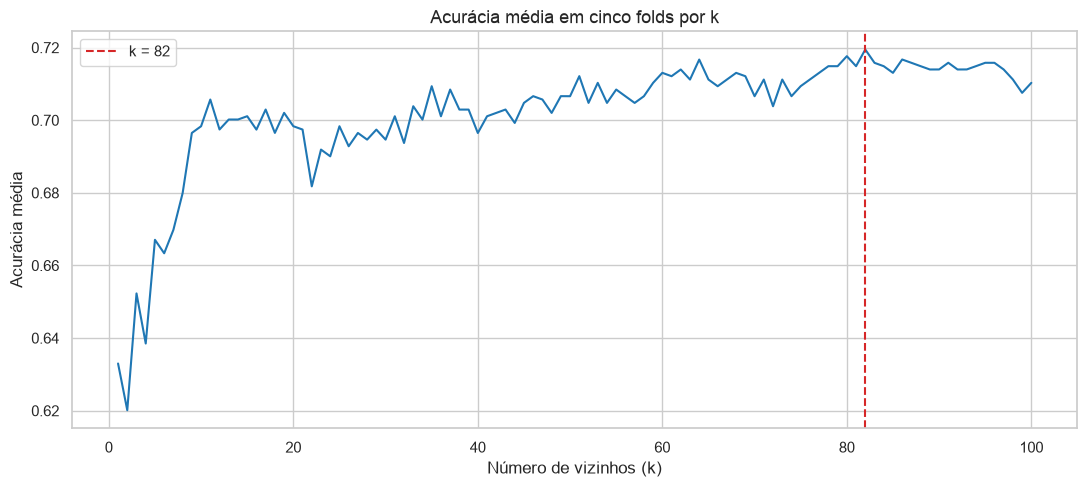

In [29]:
plt.figure(figsize=(11, 5))
sns.lineplot(x=list(k_values), y=mean_scores, color='#1f77b4')
plt.axvline(melhor_k, color='#d62728', linestyle='--', label=f'k = {melhor_k}')
plt.title('Acurácia média em cinco folds por k')
plt.xlabel('Número de vizinhos (k)')
plt.ylabel('Acurácia média')
plt.legend()
plt.tight_layout()
plt.show()


### Valor selecionado

**k = 82** obteve a maior acurácia média de validação: **0,7195**.

### Efeito do número de vizinhos

| Escolha de k | Comportamento esperado |
|---|---|
| Muito pequeno | Fronteira sensível a ruído; maior risco de sobreajuste. |
| Muito grande | Fronteira excessivamente suavizada; maior risco de subajuste e domínio das classes frequentes. |

A escolha maximiza a acurácia entre os valores testados. Como a classe bom é rara, isso não garante bom desempenho para ela.

Há uma limitação adicional: o treino contém apenas **14 vinhos bons**. Com **82 vizinhos e votação uniforme**, mesmo que todos os 14 estejam na vizinhança, os outros 68 votos se distribuem entre ruim e médio; uma dessas classes terá pelo menos 34 votos. Portanto, **a classe bom não pode vencer a votação nessa configuração**.


## Tarefa 4 — Avaliação no teste

Com k escolhido, ajustamos o pipeline em todo o treino. A matriz de confusão localiza os erros, e as métricas por classe mostram o efeito do desbalanceamento.

In [30]:
final_knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=melhor_k))
final_knn.fit(X_train, y_train)
y_pred = final_knn.predict(X_test)

print(classification_report(y_test, y_pred, labels=ordem_classes, zero_division=0))


              precision    recall  f1-score   support

        ruim       0.74      0.68      0.71       128
       médio       0.72      0.79      0.75       141
         bom       0.00      0.00      0.00         3

    accuracy                           0.73       272
   macro avg       0.49      0.49      0.49       272
weighted avg       0.72      0.73      0.72       272



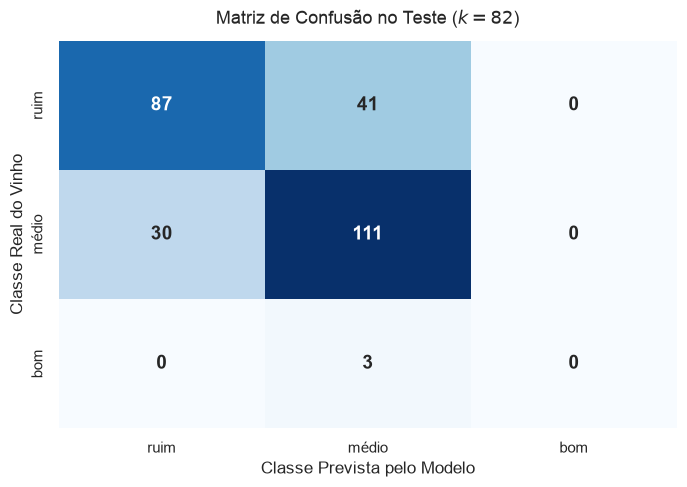

,Previsto: ruim,Previsto: médio,Previsto: bom
Real: ruim,87,41,0
Real: médio,30,111,0
Real: bom,0,3,0


In [31]:
cm = confusion_matrix(y_test, y_pred, labels=ordem_classes)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=ordem_classes,
    yticklabels=ordem_classes,
    cbar=False,
    annot_kws={"size": 14, "weight": "bold"}
)
plt.title(f"Matriz de Confusão no Teste ($k = {melhor_k}$)", fontsize=13, pad=12)
plt.xlabel("Classe Prevista pelo Modelo", fontsize=12)
plt.ylabel("Classe Real do Vinho", fontsize=12)
plt.tight_layout()
plt.show()

tabela_cm = pd.DataFrame(
    cm,
    index=[f'Real: {c}' for c in ordem_classes],
    columns=[f'Previsto: {c}' for c in ordem_classes]
)
display(tabela_cm)

### Desempenho por classe

**Acurácia geral: 0,7279.**

| Classe | Precisão | Recall | F1 |
|---|---:|---:|---:|
| Ruim | 0,7436 | 0,6797 | 0,7102 |
| Médio | 0,7161 | 0,7872 | 0,7500 |
| Bom | 0 | 0 | 0 |

### Onde o modelo erra mais

- **Ruim → médio:** 41 casos.
- **Médio → ruim:** 30 casos.
- **Bom → médio:** os três casos do teste.

O par **ruim–médio concentra 71 erros**. A acurácia global esconde a falha na classe bom: o modelo nunca a prevê. O recall zero indica que nenhum dos três bons foi reconhecido. Isso pode ocorrer devido a extrema raridade da classe no conjunto de dados.

### Consequências para a avaliação dos vinhos

| Erro | Possível impacto |
|---|---|
| Ruim → médio | Superestimar a qualidade de um lote e encaminhá-lo a uma faixa inadequada de comercialização. |
| Médio → ruim | Subestimar um lote e reduzir seu valor comercial. |
| Bom → médio | Deixar de reconhecer vinhos de qualidade superior. |

O modelo distingue parcialmente ruim de médio, mas não atende ao objetivo de reconhecer as três classes. A maior acurácia na validação não compensa a impossibilidade de prever bom com o k escolhido.